In [153]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense, Embedding, Flatten, Concatenate
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [154]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [155]:
symbols = ["AAPL","AIG", "BAC", "GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx", parse_dates=[0])
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Δημιουργία Trend
    df["Next_Volume"] = df.iloc[:, 4].shift(-1)
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

features_volume = [5, 8, 9, 10, 11, 14, 3, 15, 16, 17, 20]

X_volume_num = dataset.iloc[:, features_volume]
X_volume_sym = dataset["Symbol_enc"]
y_volume = (dataset['Next_Volume'])

dates = dataset.index

valid_idx = y_volume.notna()
X_volume_num = X_volume_num.loc[valid_idx]
X_volume_sym = X_volume_sym.loc[valid_idx]
y_volume = y_volume.loc[valid_idx]

In [156]:
print(X_volume_num)
print(X_volume_sym)
print(y_volume)

                RSI     ATR  Real Upper Band  Real Middle Band  \
Date                                                             
2019-01-02  38.1140  1.4110          43.4714           39.1471   
2019-01-03  27.9036  1.5818          42.8920           38.6381   
2019-01-04  35.1259  1.5772          42.4470           38.2987   
2019-01-07  34.9211  1.5146          42.0077           37.9789   
2019-01-08  38.2354  1.4727          41.7450           37.7671   
...             ...     ...              ...               ...   
2024-12-23  41.1601  0.4558           7.3798            6.5970   
2024-12-24  43.2908  0.4432           7.2129            6.5325   
2024-12-26  49.6211  0.4544           7.1512            6.5070   
2024-12-27  47.2697  0.4512           7.0739            6.4745   
2024-12-30  40.3978  0.4590           6.9129            6.4085   

            Real Lower Band      ADX      Close      S&P 500        VIX  \
Date                                                              

In [157]:
test_size = 0.3
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_volume_num.loc[X_volume_num.index.isin(train_dates)]
X_sym_train = X_volume_sym.loc[X_volume_sym.index.isin(train_dates)]
y_train = y_volume.loc[y_volume.index.isin(train_dates)]

X_num_test = X_volume_num.loc[X_volume_num.index.isin(test_dates)]
X_sym_test = X_volume_sym.loc[X_volume_sym.index.isin(test_dates)]
y_test = y_volume.loc[y_volume.index.isin(test_dates)]

val_size = 0.2
val_len = int(len(train_dates) * val_size)

train_dates_final = train_dates[:-val_len]
val_dates = train_dates[-val_len:]

X_num_train_final = X_volume_num.loc[X_volume_num.index.isin(train_dates_final)]
X_sym_train_final = X_volume_sym.loc[X_volume_sym.index.isin(train_dates_final)]
y_train_final = y_volume.loc[y_volume.index.isin(train_dates_final)]

X_num_val = X_volume_num.loc[X_volume_num.index.isin(val_dates)]
X_sym_val = X_volume_sym.loc[X_volume_sym.index.isin(val_dates)]
y_val = y_volume.loc[y_volume.index.isin(val_dates)]

In [158]:
test_df = pd.concat([X_num_test,X_sym_test.rename("Symbol"),y_test.rename("Target")],axis=1)

# Αποθήκευση στο Google Drive
save_path = "/content/drive/MyDrive/test_set_next_volume_aligned.csv"
test_df.to_csv(save_path)

print(f"Test set αποθηκεύτηκε στο: {save_path}")

Test set αποθηκεύτηκε στο: /content/drive/MyDrive/test_set_next_volume_aligned.csv


In [159]:
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [160]:
num_input = Input(shape=(X_num_train_final.shape[1],), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

embed_dim = 2
sym_embed = Embedding(input_dim=num_symbols,output_dim=embed_dim,name="symbol_embedding")(sym_input)
sym_embed = Flatten()(sym_embed)
x = Concatenate()([num_input, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model(inputs=[num_input, sym_input], outputs=output)
model.compile(optimizer = 'adam', loss = 'mse', metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history=model.fit([X_num_train_final, X_sym_train_final],y_train_final,validation_data=([X_num_val, X_sym_val], y_val),batch_size = 16, epochs = 1000,callbacks=[early_stopping])

Epoch 1/1000
582/582 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 2213362003869696.0000 - mae: 26926252.0000 - mape: 103635.3047 - rmse: 47046380.0000 - val_loss: 1132693874016256.0000 - val_mae: 22013524.0000 - val_mape: 99.9563 - val_rmse: 33655516.0000
Epoch 2/1000
582/582 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 2212803121250304.0000 - mae: 26917316.0000 - mape: 111508312.0000 - rmse: 47040440.0000 - val_loss: 1131716097867776.0000 - val_mae: 21992702.0000 - val_mape: 99.4414 - val_rmse: 33640988.0000
Epoch 3/1000
582/582 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 2210058368712704.0000 - mae: 26872736.0000 - mape: 902290560.0000 - rmse: 47011256.0000 - val_loss: 1128227779117056.0000 - val_mae: 21918170.0000 - val_mape: 97.5687 - val_rmse: 33589104.0000
Epoch 4/1000
582/582 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 2202922414768128.0000 - mae: 26757400.0000 - mape: 5424470528.0000 - rmse: 46935300.0000 - val_loss: 1120403154010112.0000 - val_mae: 21751268.0000 - val_mape: 93.6630 - val_rm

In [161]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([X_num_test,X_sym_test], y_test)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 321181748035584.0000 - mae: 11354325.0000 - mape: 92.5872 - rmse: 17921544.0000
Test Loss (MSE): 321181748035584.0, Test MAE: 11354325.0


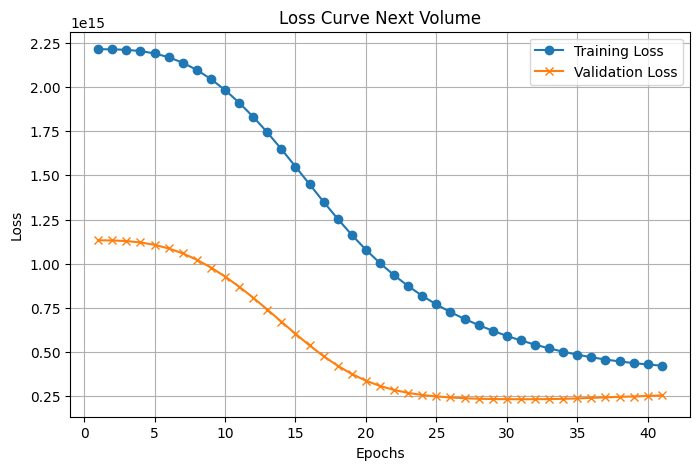

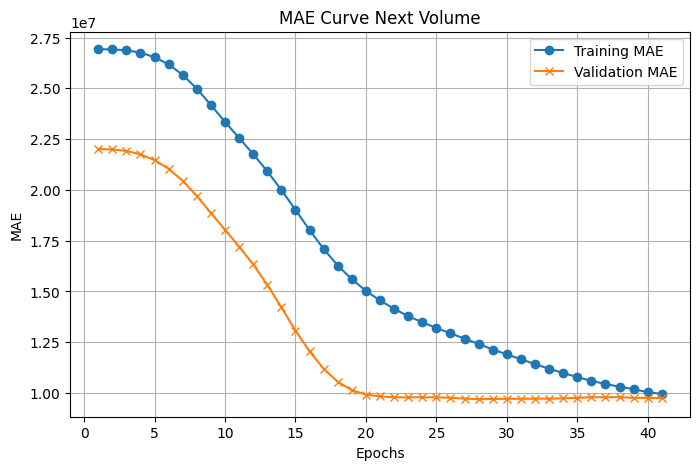

In [162]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Next Volume')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Next Volume')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [163]:
y_pred = model.predict([X_num_test,X_sym_test])

y_test = y_test.to_numpy().reshape(-1, 1)

y_test_real = y_test
y_pred_real = y_pred

mae  = mean_absolute_error((y_test_real), (y_pred_real))
rmse = np.sqrt(mean_squared_error((y_test_real), (y_pred_real)))
mape = np.mean(np.abs(((y_test_real) - (y_pred_real)) / (y_test_real))) * 100
r2   = r2_score((y_test_real), (y_pred_real))
relative_mae = mae / np.mean(y_test_real) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE : {relative_mae:.2f}%")



156/156 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE  : 11354324.39
RMSE : 17921543.10
MAPE : 92.59%
R²   : 0.380
Relative MAE : 55.00%
